# Sales Data Analysis: Superstore Orders, 2011-2014

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.float_format", "{:,.2f}".format)

In [2]:
RAW = Path("../data/raw/superstore_sales.xlsx")   # ../ because the notebook lives in notebooks/
df = pd.read_excel(RAW, sheet_name="Orders")
print(df.shape)
df.head()

(51290, 25)


,order_id,order_date,ship_date,ship_mode,customer_name,segment,state,country,market,region,...,quantity,discount,profit,shipping_cost,order_priority,year,order_month,ship_days,profit_margin,discount_band
0,AG-2011-2040,2011-01-01,2011-01-06,Standard Class,Toby Braunhardt,Consumer,Constantine,Algeria,Africa,Africa,...,2,0.00,106.14,35.46,Medium,2011,2011-01,5,0.26,0%
1,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,3,0.10,36.04,9.72,Medium,2011,2011-01,7,0.30,1-20%
2,HU-2011-1220,2011-01-01,2011-01-05,Second Class,Annie Thurman,Consumer,Budapest,Hungary,EMEA,EMEA,...,4,0.00,29.64,8.17,High,2011,2011-01,4,0.45,0%
3,IT-2011-3647632,2011-01-01,2011-01-05,Second Class,Eugene Moren,Home Office,Stockholm,Sweden,EU,North,...,3,0.50,-26.06,4.82,High,2011,2011-01,4,-0.58,41%+
4,IN-2011-47883,2011-01-01,2011-01-08,Standard Class,Joseph Holt,Consumer,New South Wales,Australia,APAC,Oceania,...,5,0.10,37.77,4.70,Medium,2011,2011-01,7,0.33,1-20%


In [3]:
required = ["order_id", "order_date", "sales", "quantity", "profit",
            "category", "sub_category", "market", "country"]
print("Missing required columns:", [c for c in required if c not in df.columns])
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
print("Date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())
df.dtypes

Missing required columns: []
Missing values: 0
Duplicate rows: 0
Date range: 2011-01-01 to 2014-12-31


order_id                     str
order_date        datetime64[us]
ship_date         datetime64[us]
ship_mode                    str
customer_name                str
segment                      str
state                        str
country                      str
market                       str
region                       str
product_id                   str
category                     str
sub_category                 str
product_name                 str
sales                    float64
quantity                   int64
discount                 float64
profit                   float64
shipping_cost            float64
order_priority               str
year                       int64
order_month                  str
ship_days                  int64
profit_margin            float64
discount_band                str
dtype: object

In [4]:
total_sales = df["sales"].sum()
total_profit = df["profit"].sum()
profit_margin = total_profit / total_sales * 100
total_units = df["quantity"].sum()
n_orders = df["order_id"].nunique()
aov = total_sales / n_orders

kpis = pd.DataFrame({
    "metric": ["Total sales", "Total profit", "Profit margin (%)",
               "Units sold", "Orders", "Average order value"],
    "value": [total_sales, total_profit, profit_margin,
              total_units, n_orders, aov],
})
kpis

,metric,value
0,Total sales,"12,642,501.91"
1,Total profit,"1,469,034.82"
2,Profit margin (%),11.62
3,Units sold,"178,312.00"
4,Orders,"25,035.00"
5,Average order value,504.99


In [5]:
wrong_margin = (df["profit"] / df["sales"]).mean() * 100
print(f"Overall margin (total profit / total sales): {profit_margin:.2f}%")
print(f"Average of row-by-row margins (misleading):  {wrong_margin:.2f}%")

Overall margin (total profit / total sales): 11.62%
Average of row-by-row margins (misleading):  4.74%


In [6]:
df["order_date"] = pd.to_datetime(df["order_date"])
df["month"] = df["order_date"].dt.to_period("M")

monthly = df.groupby("month").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
).reset_index()

print(monthly.shape)
print(monthly.head(3))
print("Sum of monthly sales:", round(monthly["sales"].sum(), 2))

(48, 3)
     month      sales    profit
0  2011-01  98,898.49  8,321.80
1  2011-02  91,152.16 12,417.91
2  2011-03 145,729.37 15,303.57
Sum of monthly sales: 12642501.91


In [7]:
df["quarter"] = df["order_date"].dt.to_period("Q")

quarterly = df.groupby("quarter").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
).reset_index()

yearly = df.groupby("year").agg(
    sales=("sales", "sum"),
    profit=("profit", "sum"),
).reset_index()
yearly["sales_growth_pct"] = yearly["sales"].pct_change() * 100

print(quarterly.shape, yearly.shape)
print("Sum of quarterly sales:", round(quarterly["sales"].sum(), 2))
print("Sum of yearly sales:", round(yearly["sales"].sum(), 2))
print(yearly.round(2))

(16, 3) (4, 4)
Sum of quarterly sales: 12642501.91
Sum of yearly sales: 12642501.91
   year        sales     profit  sales_growth_pct
0  2011 2,259,450.90 248,940.81               NaN
1  2012 2,677,438.69 307,415.28             18.50
2  2013 3,405,746.45 408,512.76             27.20
3  2014 4,299,865.87 504,165.97             26.25


In [8]:
season = df.groupby(df["order_date"].dt.month)["sales"].sum()
season_pct = (season / season.sum() * 100).round(1)
print(season_pct)
print("Sum of seasonal sales:", round(season.sum(), 2))

order_date
1     5.30
2     4.30
3     6.10
4     5.50
5     7.20
6    10.00
7     5.90
8    10.20
9    11.40
10    9.20
11   12.30
12   12.50
Name: sales, dtype: float64
Sum of seasonal sales: 12642501.91


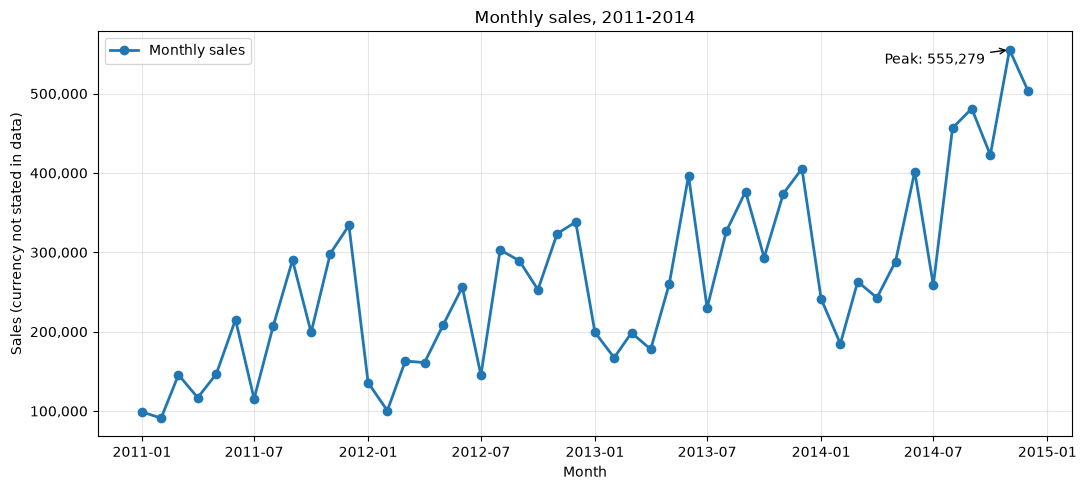

In [9]:
import matplotlib.pyplot as plt

Path("../charts").mkdir(exist_ok=True)

m = monthly.copy()
m["month_ts"] = m["month"].dt.to_timestamp()
peak = m.loc[m["sales"].idxmax()]

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(m["month_ts"], m["sales"], marker="o", linewidth=2, label="Monthly sales")
ax.annotate(f"Peak: {peak['sales']:,.0f}",
            xy=(peak["month_ts"], peak["sales"]),
            xytext=(-90, -10), textcoords="offset points",
            arrowprops=dict(arrowstyle="->"))
ax.set_title("Monthly sales, 2011-2014")
ax.set_xlabel("Month")
ax.set_ylabel("Sales (currency not stated in data)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x:,.0f}"))
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("../charts/01_monthly_sales.png", dpi=200)
plt.show()

In [10]:
peaks = monthly.loc[monthly.groupby(monthly["month"].dt.year)["sales"].idxmax()]
print(peaks)

      month      sales    profit
11  2011-12 333,925.73 40,647.98
23  2012-12 338,256.97 32,950.75
35  2013-12 405,454.38 50,202.87
46  2014-11 555,279.03 62,856.59


In [11]:
agg = dict(sales=("sales", "sum"), profit=("profit", "sum"), units=("quantity", "sum"))

cat = df.groupby("category").agg(**agg).reset_index()
cat["margin_pct"] = cat["profit"] / cat["sales"] * 100

sub = df.groupby(["category", "sub_category"]).agg(**agg).reset_index()
sub["margin_pct"] = sub["profit"] / sub["sales"] * 100
sub = sub.sort_values("sales", ascending=False)

print(cat.round(2))
print(sub.shape)
print(sub.round(2).to_string(index=False))
for name, t in [("category", cat), ("sub-category", sub)]:
    print(name, "sales:", round(t["sales"].sum(), 2),
          "| profit:", round(t["profit"].sum(), 2),
          "| units:", t["units"].sum())

          category        sales     profit   units  margin_pct
0        Furniture 4,110,874.19 286,782.25   34954        6.98
1  Office Supplies 3,787,070.23 518,473.83  108182       13.69
2       Technology 4,744,557.50 663,778.73   35176       13.99
(17, 6)
       category sub_category        sales     profit  units  margin_pct
     Technology       Phones 1,706,824.14 216,717.01  11870       12.70
     Technology      Copiers 1,509,436.27 258,567.55   7454       17.13
      Furniture       Chairs 1,501,681.76 141,973.80  12336        9.45
      Furniture    Bookcases 1,466,572.24 161,924.42   8310       11.04
Office Supplies      Storage 1,127,085.86 108,461.49  16917        9.62
Office Supplies   Appliances 1,011,064.30 141,680.59   6078       14.01
     Technology     Machines   779,060.07  58,867.87   4906        7.56
      Furniture       Tables   757,041.92 -64,083.39   3083       -8.46
     Technology  Accessories   749,237.02 129,626.31  10946       17.30
Office Supplies     

In [12]:
tables = df[df["sub_category"] == "Tables"]
others = df[df["sub_category"] != "Tables"]

print("Discount range in data:", df["discount"].min(), "to", df["discount"].max())
print("Avg discount, Tables:", round(tables["discount"].mean(), 3),
      "| others:", round(others["discount"].mean(), 3))
print("Loss-making lines, Tables:", round((tables["profit"] < 0).mean() * 100, 1), "%",
      "| others:", round((others["profit"] < 0).mean() * 100, 1), "%")

bands = pd.cut(tables["discount"], [-0.001, 0, 0.2, 0.4, 1.0],
               labels=["0%", "0-20%", "20-40%", "over 40%"])
by_band = tables.groupby(bands, observed=True).agg(
    lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
print(by_band.round(2))
print("Lines in bands:", by_band["lines"].sum(), "| Tables rows:", len(tables))

Discount range in data: 0.0 to 0.85
Avg discount, Tables: 0.291 | others: 0.14
Loss-making lines, Tables: 57.6 % | others: 23.9 %
          lines      sales     profit
discount                             
0%          208 261,809.35  60,447.20
0-20%       186 161,204.14   8,010.56
20-40%      246 211,066.78 -38,188.31
over 40%    221 122,961.65 -94,352.84
Lines in bands: 861 | Tables rows: 861


In [13]:
mkt = df.groupby("market").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
mkt["margin_pct"] = mkt["profit"] / mkt["sales"] * 100
reg = df.groupby("region").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
reg["margin_pct"] = reg["profit"] / reg["sales"] * 100

print(mkt.sort_values("sales", ascending=False).round(2).to_string(index=False))
print(reg.shape)
for name, t in [("market", mkt), ("region", reg)]:
    print(name, "sales:", round(t["sales"].sum(), 2), "| profit:", round(t["profit"].sum(), 2))

market        sales     profit  margin_pct
  APAC 3,585,744.13 437,577.58       12.20
    EU 2,938,089.06 372,829.74       12.69
    US 2,297,200.86 286,397.02       12.47
 LATAM 2,164,605.17 221,643.49       10.24
  EMEA   806,161.31  43,897.97        5.45
Africa   783,773.21  88,871.63       11.34
Canada    66,928.17  17,817.39       26.62
(13, 4)
market sales: 12642501.91 | profit: 1469034.82
region sales: 12642501.91 | profit: 1469034.82


In [14]:
ctry = df.groupby("country").agg(sales=("sales", "sum"), profit=("profit", "sum")).reset_index()
ctry["margin_pct"] = ctry["profit"] / ctry["sales"] * 100

print(ctry.shape)
print(ctry.sort_values("sales", ascending=False).head(10).round(2).to_string(index=False))
print("country sales:", round(ctry["sales"].sum(), 2), "| profit:", round(ctry["profit"].sum(), 2))

(147, 4)
       country        sales     profit  margin_pct
 United States 2,297,200.86 286,397.02       12.47
     Australia   925,235.85 105,484.96       11.40
        France   858,931.08 109,029.00       12.69
         China   700,562.02 150,683.08       21.51
       Germany   628,840.03 107,322.82       17.07
        Mexico   622,590.62 102,818.10       16.51
         India   589,650.10 129,071.84       21.89
United Kingdom   528,576.30 111,900.15       21.17
     Indonesia   404,887.50  15,608.68        3.86
        Brazil   361,106.42  30,090.50        8.33
country sales: 12642501.91 | profit: 1469034.82


In [15]:
bands = pd.cut(df["discount"], [-0.001, 0, 0.2, 0.4, 1.0],
               labels=["0%", "0-20%", "20-40%", "over 40%"])
all_bands = df.groupby(bands, observed=True).agg(
    lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
all_bands["margin_pct"] = all_bands["profit"] / all_bands["sales"] * 100

print(all_bands.round(2))
print("Lines:", all_bands["lines"].sum(), "| sales:", round(all_bands["sales"].sum(), 2),
      "| profit:", round(all_bands["profit"].sum(), 2))

          lines        sales       profit  margin_pct
discount                                             
0%        29009 6,992,410.95 1,770,695.27       25.32
0-20%     10953 3,719,880.18   513,021.63       13.79
20-40%     4367 1,083,897.81  -187,271.06      -17.28
over 40%   6961   846,312.97  -627,411.02      -74.13
Lines: 51290 | sales: 12642501.91 | profit: 1469034.82


In [16]:
import numpy as np
Path("../reports").mkdir(exist_ok=True)

tot = df[["sales", "profit", "quantity"]].sum()
rows = []
for col in ["month", "quarter", "year", "category", "sub_category",
            "market", "region", "country", "segment", "ship_mode"]:
    g = df.groupby(col)[["sales", "profit", "quantity"]].sum()
    assert np.isclose(g["sales"].sum(), tot["sales"]), f"sales mismatch: {col}"
    assert np.isclose(g["profit"].sum(), tot["profit"]), f"profit mismatch: {col}"
    assert g["quantity"].sum() == tot["quantity"], f"units mismatch: {col}"
    rows.append({"grouped_by": col, "groups": len(g),
                 "sales": round(g["sales"].sum(), 2),
                 "profit": round(g["profit"].sum(), 2),
                 "units": int(g["quantity"].sum())})

recon = pd.DataFrame(rows)
recon.to_csv("../reports/reconciliation.csv", index=False)
print(recon.to_string(index=False))
print("ALL RECONCILIATION CHECKS PASSED")

  grouped_by  groups         sales       profit  units
       month      48 12,642,501.91 1,469,034.82 178312
     quarter      16 12,642,501.91 1,469,034.82 178312
        year       4 12,642,501.91 1,469,034.82 178312
    category       3 12,642,501.91 1,469,034.82 178312
sub_category      17 12,642,501.91 1,469,034.82 178312
      market       7 12,642,501.91 1,469,034.82 178312
      region      13 12,642,501.91 1,469,034.82 178312
     country     147 12,642,501.91 1,469,034.82 178312
     segment       3 12,642,501.91 1,469,034.82 178312
   ship_mode       4 12,642,501.91 1,469,034.82 178312
ALL RECONCILIATION CHECKS PASSED


In [17]:
df["disc_gt20"] = df["discount"] > 0.2
for key in ["market", "country"]:
    t = df.groupby(key).agg(avg_discount=("discount", "mean"),
                            share_lines_gt20=("disc_gt20", "mean"),
                            profit=("profit", "sum"),
                            sales=("sales", "sum"))
    t["margin_pct"] = t["profit"] / t["sales"] * 100
    t["share_lines_gt20"] *= 100
    if key == "market":
        print(t.sort_values("margin_pct").round(2))
    else:
        print(t.loc[["Indonesia", "Brazil", "China", "India", "United States"]].round(2))

        avg_discount  share_lines_gt20     profit        sales  margin_pct
market                                                                    
EMEA            0.20             31.99  43,897.97   806,161.31        5.45
LATAM           0.14             25.80 221,643.49 2,164,605.17       10.24
Africa          0.16             22.28  88,871.63   783,773.21       11.34
APAC            0.15             27.73 437,577.58 3,585,744.13       12.20
US              0.16             13.94 286,397.02 2,297,200.86       12.47
EU              0.10             15.97 372,829.74 2,938,089.06       12.69
Canada          0.00              0.00  17,817.39    66,928.17       26.62
               avg_discount  share_lines_gt20     profit        sales  \
country                                                                 
Indonesia              0.30             59.14  15,608.68   404,887.50   
Brazil                 0.15             23.76  30,090.50   361,106.42   
China                  0.01      

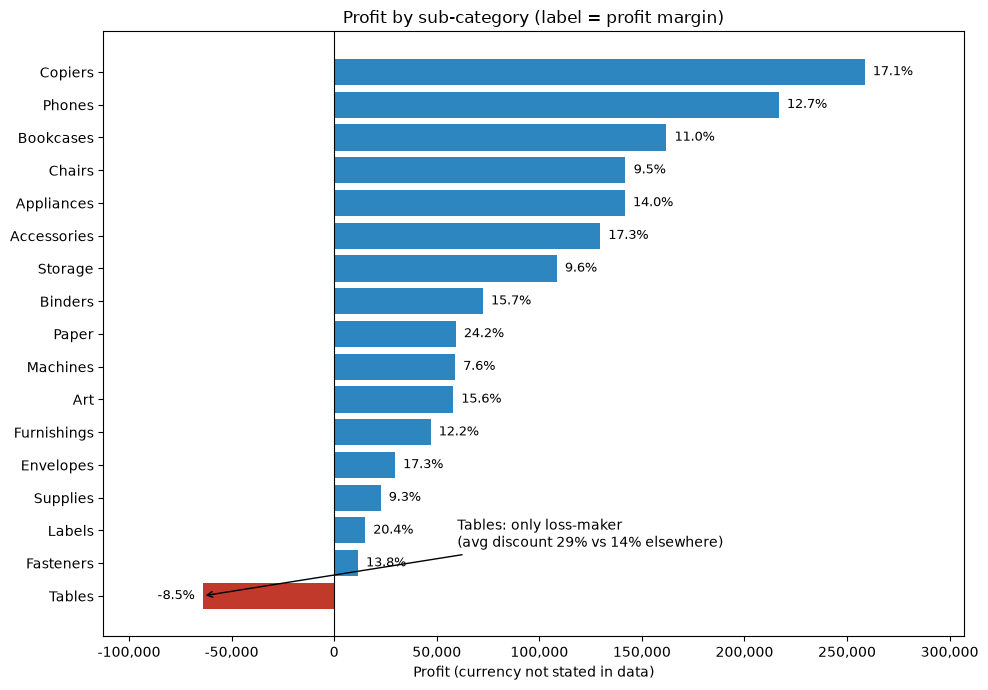

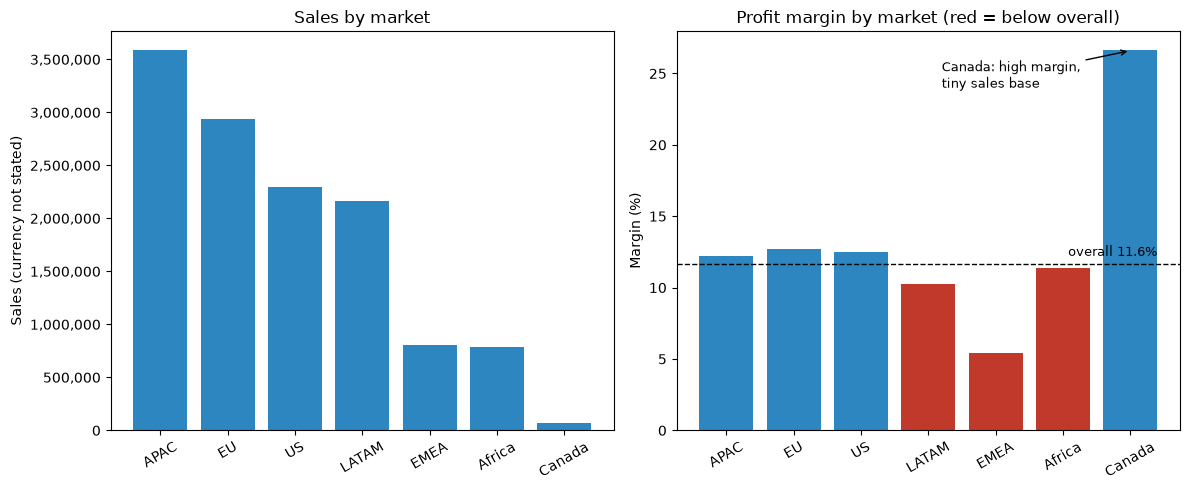

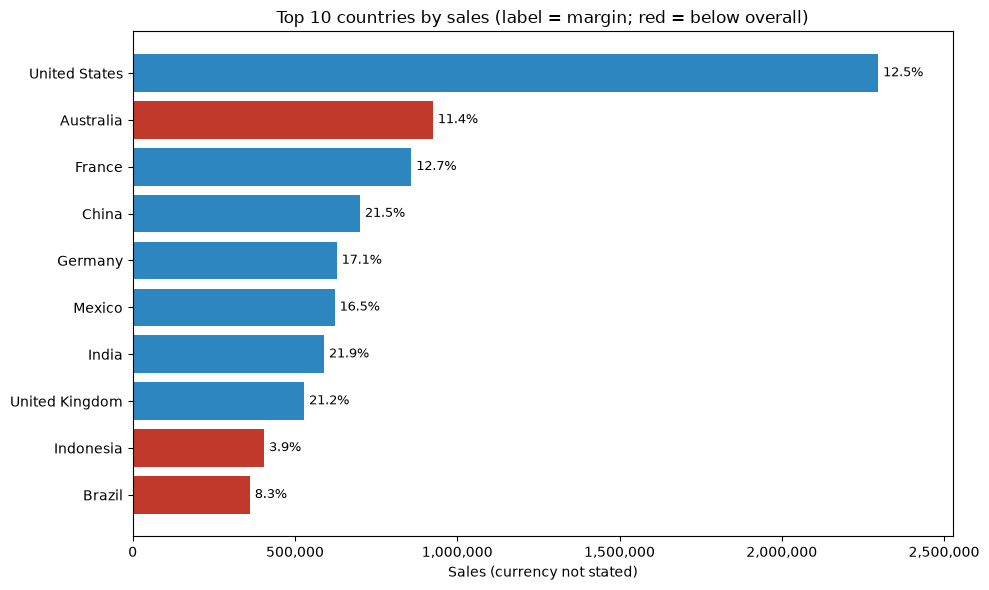

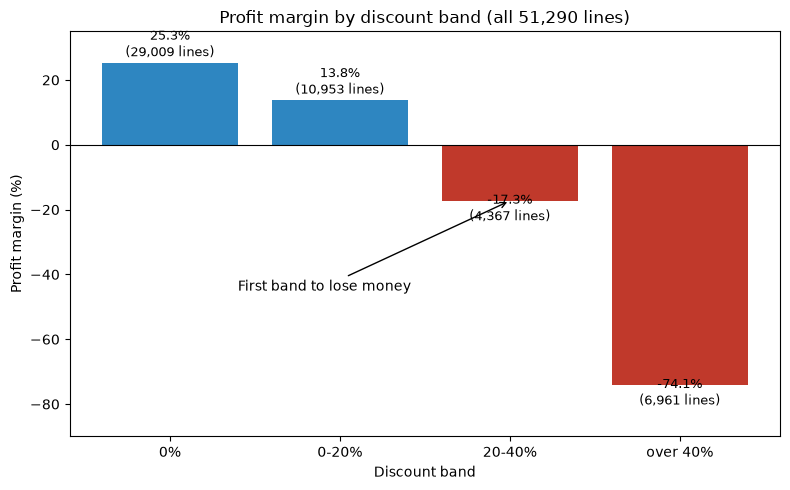

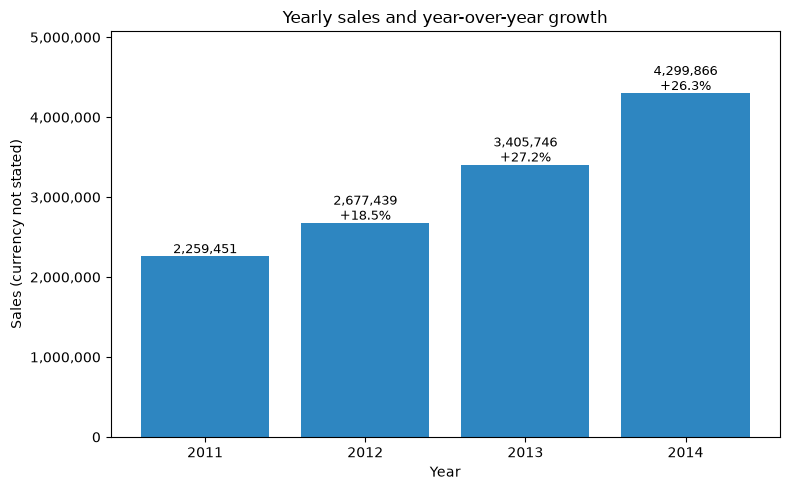

In [18]:
import matplotlib.ticker as mt
overall = tot["profit"] / tot["sales"] * 100
fmt = mt.FuncFormatter(lambda x, _: f"{x:,.0f}")
RED, BLUE, GREY = "#c0392b", "#2e86c1", "#7f8c8d"

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(f"../charts/{name}", dpi=200, bbox_inches="tight")
    plt.show()

# 02: profit by sub-category
s = sub.sort_values("profit")
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(s["sub_category"], s["profit"],
        color=[RED if p < 0 else BLUE for p in s["profit"]])
for y, (p, m) in enumerate(zip(s["profit"], s["margin_pct"])):
    ax.text(p + (4000 if p >= 0 else -4000), y, f"{m:.1f}%", va="center",
            ha="left" if p >= 0 else "right", fontsize=9)
ax.axvline(0, color="black", lw=0.8)
yt = list(s["sub_category"]).index("Tables")
ax.annotate("Tables: only loss-maker\n(avg discount 29% vs 14% elsewhere)",
            xy=(s["profit"].iloc[yt], yt), xytext=(60000, yt + 1.5),
            arrowprops=dict(arrowstyle="->"))
ax.margins(x=0.15)
ax.xaxis.set_major_formatter(fmt)
ax.set_title("Profit by sub-category (label = profit margin)")
ax.set_xlabel("Profit (currency not stated in data)")
finish(fig, "02_profit_by_subcategory.png")

# 03: market sales and margin
m = mkt.sort_values("sales", ascending=False)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 5))
a1.bar(m["market"], m["sales"], color=BLUE)
a1.yaxis.set_major_formatter(fmt)
a1.set_title("Sales by market"); a1.set_ylabel("Sales (currency not stated)")
a2.bar(m["market"], m["margin_pct"], color=[RED if v < overall else BLUE for v in m["margin_pct"]])
a2.axhline(overall, color="black", ls="--", lw=1)
a2.text(6.4, overall + 0.6, f"overall {overall:.1f}%", ha="right", fontsize=9)
a2.set_title("Profit margin by market (red = below overall)"); a2.set_ylabel("Margin (%)")
a2.annotate("Canada: high margin,\ntiny sales base", xy=(list(m["market"]).index("Canada"), 26.6),
            xytext=(3.2, 24), arrowprops=dict(arrowstyle="->"), fontsize=9)
for a in (a1, a2): a.tick_params(axis="x", rotation=30)
finish(fig, "03_markets.png")

# 04: top 10 countries
c = ctry.sort_values("sales", ascending=False).head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(c["country"], c["sales"], color=[RED if v < overall else BLUE for v in c["margin_pct"]])
for y, (v, mg) in enumerate(zip(c["sales"], c["margin_pct"])):
    ax.text(v + 15000, y, f"{mg:.1f}%", va="center", fontsize=9)
ax.margins(x=0.1); ax.xaxis.set_major_formatter(fmt)
ax.set_title("Top 10 countries by sales (label = margin; red = below overall)")
ax.set_xlabel("Sales (currency not stated)")
finish(fig, "04_top_countries.png")

# 05: discount vs margin
fig, ax = plt.subplots(figsize=(8, 5))
vals = all_bands["margin_pct"]
ax.bar(vals.index.astype(str), vals, color=[RED if v < 0 else BLUE for v in vals])
for i, (v, n) in enumerate(zip(vals, all_bands["lines"])):
    ax.text(i, v + (2 if v >= 0 else -6), f"{v:.1f}%\n({n:,} lines)", ha="center", fontsize=9)
ax.axhline(0, color="black", lw=0.8); ax.set_ylim(-90, 35)
ax.set_title("Profit margin by discount band (all 51,290 lines)")
ax.set_xlabel("Discount band"); ax.set_ylabel("Profit margin (%)")
ax.annotate("First band to lose money", xy=(2, -17.3), xytext=(0.4, -45),
            arrowprops=dict(arrowstyle="->"))
finish(fig, "05_discount_vs_margin.png")

# 06: yearly sales with growth
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(yearly["year"].astype(str), yearly["sales"], color=BLUE)
for i, (v, g) in enumerate(zip(yearly["sales"], yearly["sales_growth_pct"])):
    ax.text(i, v + 40000, f"{v:,.0f}" + ("" if np.isnan(g) else f"\n+{g:.1f}%"), ha="center", fontsize=9)
ax.set_ylim(0, yearly["sales"].max() * 1.18); ax.yaxis.set_major_formatter(fmt)
ax.set_title("Yearly sales and year-over-year growth")
ax.set_xlabel("Year"); ax.set_ylabel("Sales (currency not stated)")
finish(fig, "06_yearly_sales.png")